In [4]:
import pickle
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset (using ../ to move up from notebooks/ to root)
df_clean = pd.read_csv('../data/house_prices_dataset.csv')

# Feature Engineering
if 'zipcode' in df_clean.columns:
  df_clean = df_clean.drop(columns=['zipcode'])

df_clean['house_age'] = 2026 - df_clean['year_built']
df_clean['is_renovated'] = (df_clean['year_renovated'] > 0).astype(int)

# Separate features (X) and target (y)
X = df_clean.drop(columns=['price'])
y = df_clean['price']

# Train / Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model Training and Leaderboard Evaluation
models = {
    'Linear Regression': (LinearRegression(), True),
    'Ridge Regression (α=1.0)': (Ridge(alpha=1.0), True),
    'Lasso Regression (α=1000.0)': (Lasso(alpha=1000.0, max_iter=10000), True),
    'Gradient Boosting Regressor': (
        GradientBoostingRegressor(n_estimators=100, random_state=42),
        False,
    ),
    'Random Forest Regressor': (
        RandomForestRegressor(n_estimators=100, random_state=42),
        False,
    ),
}

results = []
for name, (model, is_scaled) in models.items():
  if is_scaled:
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
  else:
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

  mae = mean_absolute_error(y_test, preds)
  rmse = np.sqrt(mean_squared_error(y_test, preds))
  r2 = r2_score(y_test, preds)
  results.append({'Model': name, 'MAE ($)': mae, 'RMSE ($)': rmse, 'R2 Score': r2})

pd.DataFrame(results)

,Model,MAE ($),RMSE ($),R2 Score
0,Linear Regression,15387.957968,19162.800051,0.996580
1,Ridge Regression (α=1.0),15419.862382,19194.905588,0.996569
2,Lasso Regression (α=1000.0),15566.966168,19435.911873,0.996482
3,Gradient Boosting Regressor,21951.015809,27843.455106,0.992780
4,Random Forest Regressor,28763.356161,36844.420301,0.987358


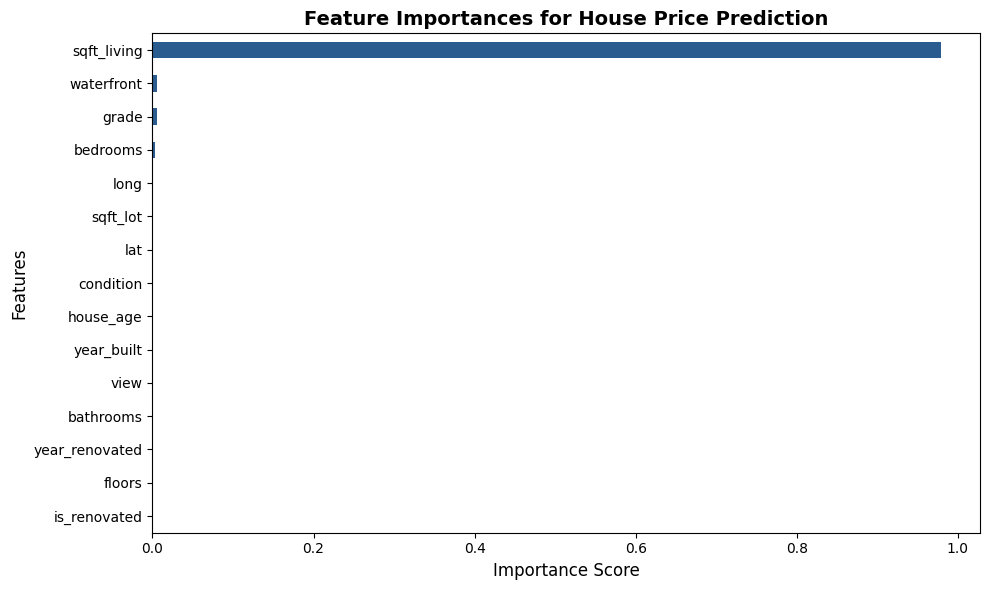

In [5]:
# Feature Importance Extraction using Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(
    ascending=True
)

plt.figure(figsize=(10, 6))
importances.plot(kind='barh', color='#2b5c8f')
plt.title(
    'Feature Importances for House Price Prediction',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()